DISCLAIMER CODE FOR EDUCATIONAL PURPUOSE ONLY
NOT A FINANCIAL ADVICE
NO LIABILITY

Thanks to QWEN ai that debug this code!

Installing packages...
ELECTRICITY TRADING - ROLLING WINDOW & DIAGNOSTICS SOLUTION-!!NAIVE LEAKY CODE!!!

[1/8] Loading data...
Total data shape: (24070, 81)

[2/8] Splitting data (70% Train / 30% Test)...

[3/8] Creating features from ALL dataset columns...
Total features generated: 500

[4/8] Performing Rolling Window Training on 70% Train Data...
Rolling Window Validation MAE: 0.61 | RMSE: 3.43
Rolling Window Validation PnL: €1,953,403

[5/8] Training Final Ensemble on Full 70% Train Data...

[6/8] Predicting on 30% Test Data...

[7/8] Running Feature Diagnostics & Residual Analysis...

--- FEATURE DIAGNOSTICS REPORT ---
Zero-variance features (dropped/ignored by trees): 4
Highly correlated feature pairs (>0.95): 123
Top 3 highly correlated pairs:
                  Feature1                   Feature2  Correlation
flow_abs_dk1_no2_mw_lag168 utilization_dk1_no2_lag168          1.0
flow_abs_dk1_dk2_mw_lag168 utilization_dk1_dk2_lag168          1.0
  flow_abs_dk1_no2_mw_lag1   utilizati

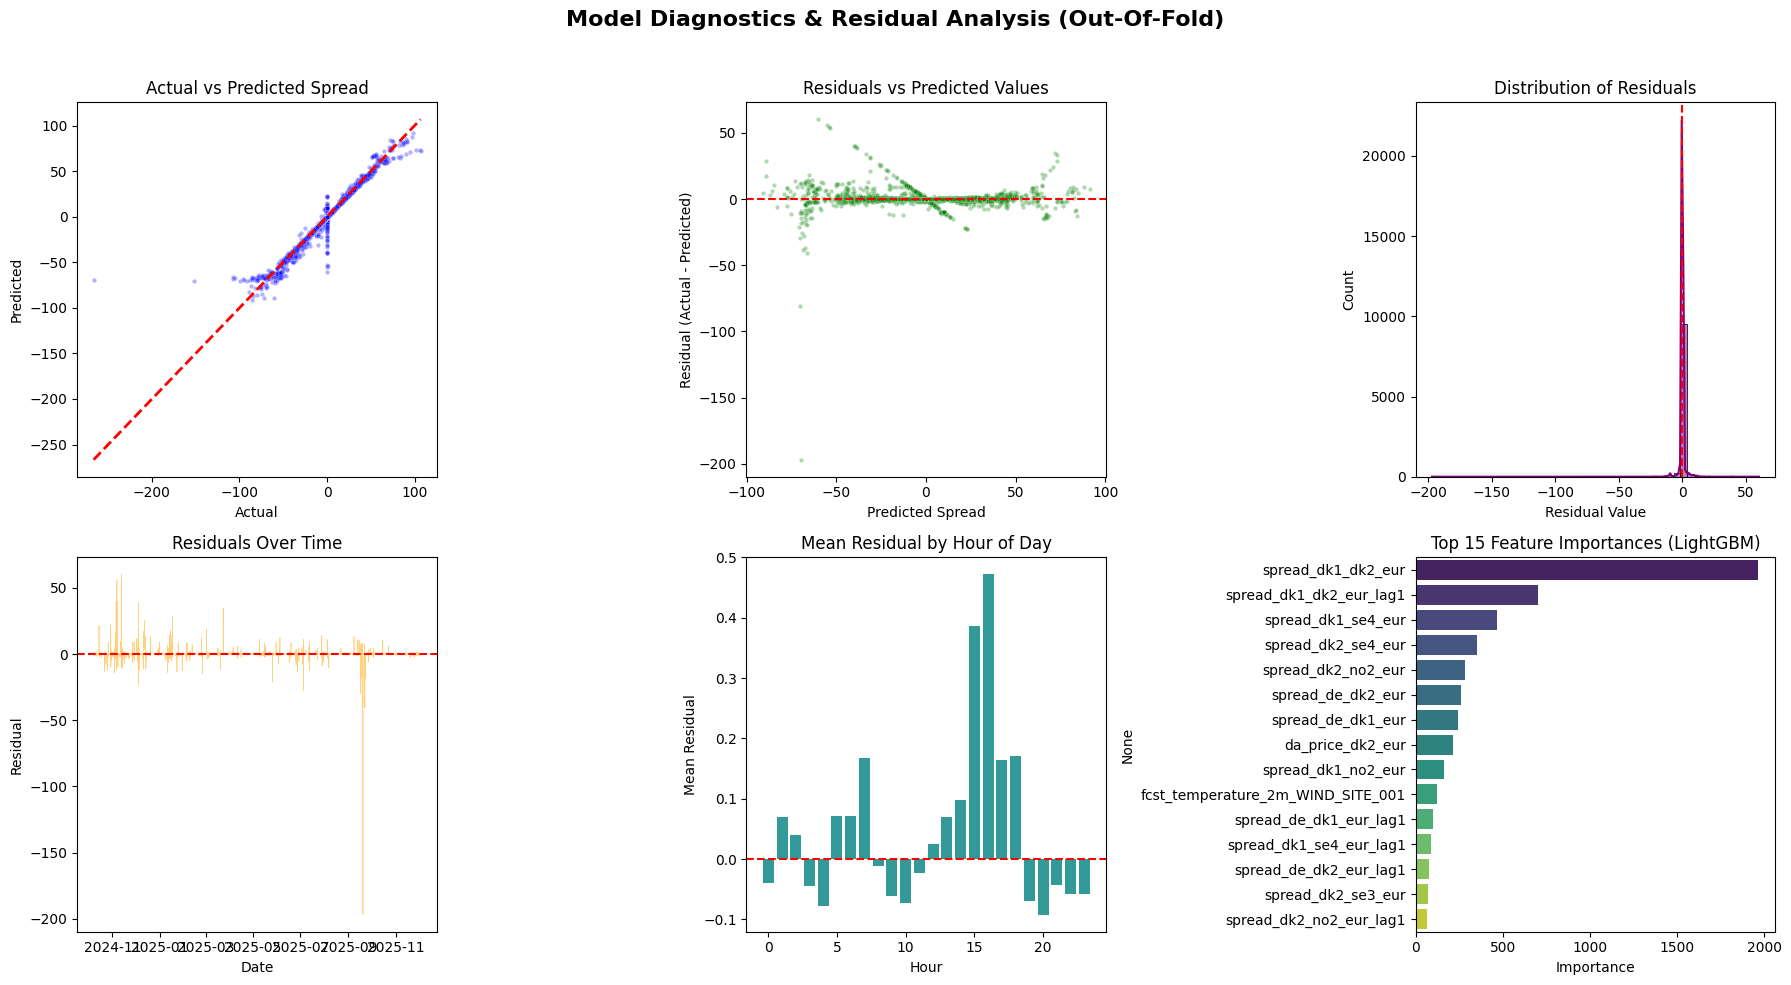

Diagnostics plot saved to /kaggle/working/diagnostics.png

[8/8] Creating submission...

PIPELINE COMPLETE!
Files generated:
  - /kaggle/working/submission.csv
  - /kaggle/working/diagnostics.png


In [1]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
Electricity Trading Challenge - Rolling Window, Full Features & Diagnostics
"""
#############LEAKY CODE DEMONSTRATION############## WARNING 
################################################### WARNING
import subprocess
import sys

print("Installing packages...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], capture_output=True)

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import seaborn as sns

print("="*80)
print("ELECTRICITY TRADING - ROLLING WINDOW & DIAGNOSTICS SOLUTION-!!NAIVE LEAKY CODE!!!")
print("="*80)

# =====================================
# 1. LOAD DATA & COMPUTE TARGET/IMBALANCE
# =====================================
print("\n[1/8] Loading data...")
df = pd.read_csv('/kaggle/input/datasets/michelemil/dk-el-trade-dataset/04_denmark_energy_ml_with_weather.csv', 
                 parse_dates=['delivery_ts'], index_col=0)

print(f"Total data shape: {df.shape}")

# Compute Target (Spread) and Imbalance Proxy
df['spread'] = df['da_price_dk1_eur'] - df['da_price_dk2_eur']
flow_cols = [c for c in df.columns if c.startswith('flow_dk1_')]
df['imbalance'] = df[flow_cols].sum(axis=1).abs() if flow_cols else df['spread'].abs() * 10 

# =====================================
# 2. TRAIN / TEST SPLIT (70% / 30%)
# =====================================
print("\n[2/8] Splitting data (70% Train / 30% Test)...")
split_idx = int(len(df) * 0.70)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()

# =====================================
# 3. FEATURE ENGINEERING (ALL FEATURES)
# =====================================
print("\n[3/8] Creating features from ALL dataset columns...")

def create_features(df, target_col='spread'):
    df = df.copy()
    df['hour'] = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['month'] = df.index.month
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
    
    df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
    df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)
    df['month_sin'] = np.sin(2 * np.pi * df['month'] / 12)
    df['month_cos'] = np.cos(2 * np.pi * df['month'] / 12)
    
    exclude_cols = [target_col, 'imbalance']
    num_cols = [c for c in df.select_dtypes(include=[np.number]).columns if c not in exclude_cols]
    
    for lag in [1, 24, 168]: 
        for col in num_cols:
            df[f'{col}_lag{lag}'] = df[col].shift(lag)
            
    key_cols = [c for c in num_cols if 'price' in c or 'flow' in c or 'wind' in c]
    for w in [24, 168]:
        for col in key_cols:
            df[f'{col}_ma{w}'] = df[col].rolling(w, min_periods=1).mean()
            df[f'{col}_std{w}'] = df[col].rolling(w, min_periods=1).std()
            
    return df.fillna(0).replace([np.inf, -np.inf], 0)

X_train_full = create_features(train_df)
y_train_full = X_train_full['spread'].copy()
imb_train_full = X_train_full['imbalance'].copy()
X_train_full = X_train_full.drop(['spread', 'imbalance'], axis=1)

X_test = create_features(test_df)
X_test = X_test.drop(['spread', 'imbalance'], axis=1)

for col in X_train_full.columns:
    if col not in X_test.columns: X_test[col] = 0
X_test = X_test[X_train_full.columns]

print(f"Total features generated: {X_train_full.shape[1]}")

# =====================================
# 4. ROLLING WINDOW TRAINING & VALIDATION
# =====================================
print("\n[4/8] Performing Rolling Window Training on 70% Train Data...")

window_size = int(0.4 * len(X_train_full)) 
step_size = int(0.1 * len(X_train_full))   

oof_preds = np.zeros(len(X_train_full))
oof_mask = np.zeros(len(X_train_full), dtype=bool)

import lightgbm as lgb

for start in range(0, len(X_train_full) - step_size, step_size):
    end = min(start + window_size, len(X_train_full))
    X_tr = X_train_full.iloc[start:end]
    y_tr = y_train_full.iloc[start:end]
    
    pred_start = end
    pred_end = min(end + step_size, len(X_train_full))
    if pred_start >= len(X_train_full): break
        
    X_pred = X_train_full.iloc[pred_start:pred_end]
    
    model = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, max_depth=8, verbosity=-1, n_jobs=-1)
    model.fit(X_tr, y_tr)
    
    oof_preds[pred_start:pred_end] = model.predict(X_pred)
    oof_mask[pred_start:pred_end] = True

y_val_rolling = y_train_full[oof_mask]
preds_rolling = oof_preds[oof_mask]
imb_rolling = imb_train_full[oof_mask]

mae = mean_absolute_error(y_val_rolling, preds_rolling)
rmse = np.sqrt(mean_squared_error(y_val_rolling, preds_rolling))
print(f"Rolling Window Validation MAE: {mae:.2f} | RMSE: {rmse:.2f}")

pnl = 0
for i in range(len(preds_rolling)):
    if abs(imb_rolling.iloc[i]) <= 1000:
        pnl += (50 * y_val_rolling.iloc[i]) if preds_rolling[i] >= 0 else (-50 * y_val_rolling.iloc[i])
print(f"Rolling Window Validation PnL: €{pnl:,.0f}")

# =====================================
# 5. FINAL ENSEMBLE TRAINING (Full 70%)
# =====================================
print("\n[5/8] Training Final Ensemble on Full 70% Train Data...")

models = []
models.append(('lgbm', lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=8, num_leaves=60, subsample=0.8, colsample_bytree=0.7, verbosity=-1, n_jobs=-1), 0.40))

try:
    import xgboost as xgb
    models.append(('xgb', xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=8, subsample=0.8, colsample_bytree=0.7, n_jobs=-1, verbosity=0), 0.30))
except: pass

#models.append(('rf', RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_split=20, n_jobs=-1), 0.20))
models.append(('ridge', Ridge(alpha=10.0), 0.10))

total_weight = sum([w for _, _, w in models])
models = [(name, model, w/total_weight) for name, model, w in models]

trained_models = []
for name, model, weight in models:
    model.fit(X_train_full, y_train_full)
    trained_models.append((name, model, weight))

# =====================================
# 6. PREDICT ON 30% TEST DATA
# =====================================
print("\n[6/8] Predicting on 30% Test Data...")
test_preds = [model.predict(X_test) * weight for name, model, weight in trained_models]
predictions = np.clip(np.sum(test_preds, axis=0), np.percentile(y_train_full, 1), np.percentile(y_train_full, 99))

# =====================================
# 7. FEATURE DIAGNOSTICS & RESIDUAL ANALYSIS
# =====================================
print("\n[7/8] Running Feature Diagnostics & Residual Analysis...")

# --- A. Console Diagnostics Report ---
print("\n--- FEATURE DIAGNOSTICS REPORT ---")
# 1. Zero Variance Check
zero_var_cols = [col for col in X_train_full.columns if X_train_full[col].std() == 0]
print(f"Zero-variance features (dropped/ignored by trees): {len(zero_var_cols)}")

# 2. High Correlation Check
corr_matrix = X_train_full.corr().abs()
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))
high_corr_pairs = upper.stack().reset_index()
high_corr_pairs.columns = ['Feature1', 'Feature2', 'Correlation']
high_corr_pairs = high_corr_pairs[high_corr_pairs['Correlation'] > 0.95].sort_values('Correlation', ascending=False)
print(f"Highly correlated feature pairs (>0.95): {len(high_corr_pairs)}")
if len(high_corr_pairs) > 0:
    print("Top 3 highly correlated pairs:")
    print(high_corr_pairs.head(3).to_string(index=False))

# --- B. Residual Calculations (Using OOF predictions to avoid overfitting leakage) ---
residuals = y_val_rolling.values - preds_rolling
residuals_series = pd.Series(residuals, index=y_val_rolling.index)

print("\n--- RESIDUAL STATISTICS ---")
print(f"Mean Residual: {np.mean(residuals):.4f} (Should be close to 0)")
print(f"Std Residual:  {np.std(residuals):.4f}")
print(f"Skewness:      {pd.Series(residuals).skew():.4f}")
print(f"Kurtosis:      {pd.Series(residuals).kurtosis():.4f}")

# --- C. Diagnostic Plots ---
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Diagnostics & Residual Analysis (Out-Of-Fold)', fontsize=16, fontweight='bold')

# Plot 1: Actual vs Predicted
sns.scatterplot(x=y_val_rolling.values, y=preds_rolling, ax=axes[0, 0], alpha=0.3, s=10, color='blue')
axes[0, 0].plot([y_val_rolling.min(), y_val_rolling.max()], [y_val_rolling.min(), y_val_rolling.max()], 'r--', lw=2)
axes[0, 0].set_title('Actual vs Predicted Spread')
axes[0, 0].set_xlabel('Actual')
axes[0, 0].set_ylabel('Predicted')

# Plot 2: Residuals vs Predicted (Check for heteroscedasticity)
sns.scatterplot(x=preds_rolling, y=residuals, ax=axes[0, 1], alpha=0.3, s=10, color='green')
axes[0, 1].axhline(0, color='red', linestyle='--')
axes[0, 1].set_title('Residuals vs Predicted Values')
axes[0, 1].set_xlabel('Predicted Spread')
axes[0, 1].set_ylabel('Residual (Actual - Predicted)')

# Plot 3: Distribution of Residuals
sns.histplot(residuals, bins=50, kde=True, ax=axes[0, 2], color='purple')
axes[0, 2].axvline(0, color='red', linestyle='--')
axes[0, 2].set_title('Distribution of Residuals')
axes[0, 2].set_xlabel('Residual Value')

# Plot 4: Residuals over Time (Check for temporal patterns)
axes[1, 0].plot(residuals_series.index, residuals_series.values, alpha=0.5, color='orange', linewidth=0.5)
axes[1, 0].axhline(0, color='red', linestyle='--')
axes[1, 0].set_title('Residuals Over Time')
axes[1, 0].set_xlabel('Date')
axes[1, 0].set_ylabel('Residual')

# Plot 5: Mean Residual by Hour (Check for time-of-day bias)
hourly_res = residuals_series.groupby(residuals_series.index.hour).mean()
axes[1, 1].bar(hourly_res.index, hourly_res.values, color='teal', alpha=0.8)
axes[1, 1].axhline(0, color='red', linestyle='--')
axes[1, 1].set_title('Mean Residual by Hour of Day')
axes[1, 1].set_xlabel('Hour')
axes[1, 1].set_ylabel('Mean Residual')

# Plot 6: Feature Importance (Top 15 from LightGBM)
lgb_final = [m for n, m, w in trained_models if n == 'lgbm'][0]
importances = lgb_final.feature_importances_
feature_names = X_train_full.columns
top_features = pd.Series(importances, index=feature_names).nlargest(15)
sns.barplot(x=top_features.values, y=top_features.index, ax=axes[1, 2], palette='viridis')
axes[1, 2].set_title('Top 15 Feature Importances (LightGBM)')
axes[1, 2].set_xlabel('Importance')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('/kaggle/working/diagnostics.png', dpi=150)
plt.show()
print("Diagnostics plot saved to /kaggle/working/diagnostics.png")

# =====================================
# 8. SAVE SUBMISSION
# =====================================
print("\n[8/8] Creating submission...")
submission = pd.DataFrame({'forecast': predictions})
submission.index.name = 'ID'
submission.to_csv('/kaggle/working/submission.csv')

print("\n" + "="*80)
print("PIPELINE COMPLETE!")
print("="*80)
print(f"Files generated:\n  - /kaggle/working/submission.csv\n  - /kaggle/working/diagnostics.png")

Installing packages...
ELECTRICITY TRADING - LEAKAGE-AUDITED PIPELINE

[1/9] Loading data...
  Realized (must be lagged >=24h): 53 | Day-ahead forecasts: 28

[2/9] Creating strictly causal features...
  Features: 417 | Train: 16714 | Test: 7164

[3/9] Leakage audit...
  Raw realized columns left in X: NONE ✓
  Top |corr| with target:
spread_lag24                         0.155355
spread_dk1_dk2_eur_lag24             0.155355
fcst_windspeed_100m_REG_SE4_SOUTH    0.146399
fcst_windspeed_10m_REG_SE4_SOUTH     0.144997
hour_cos                             0.132351
spread_dk1_dk2_eur_ma24              0.131525
spread_ma24                          0.131525
spread_dk1_dk2_eur_lag48             0.128727
  Audit passed: no contemporaneous target proxy in features ✓

[4/9] Feature pruning...
  Dropping 89 features.
  Pruned features: 328

[5/9] Rolling window validation...
  Rolling MAE: 8.34 | RMSE: 15.21 | IC: 0.1702  (realistic IC << 0.9 expected)

[6/9] Training final ensemble...

[7/9] Predi

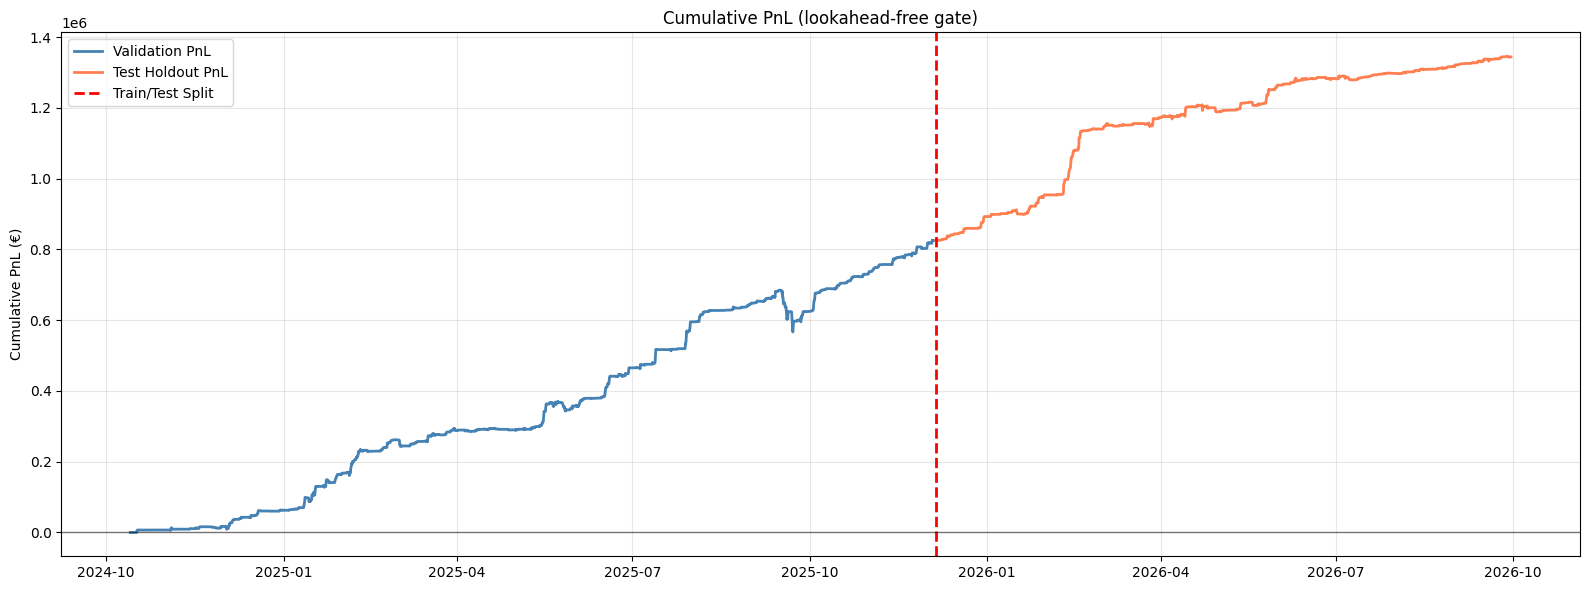


[9/9] Saving submission...
Pipeline complete.


In [2]:
#!/usr/bin/env python
# -*- coding: utf-8 -*-
"""
Electricity Trading Challenge - Leakage-Audited Pipeline (KeyError fixed)
Information horizon: decision for delivery hour t is made at t-24.
"""

import subprocess, sys
print("Installing packages...")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "lightgbm"], capture_output=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "xgboost"], capture_output=True)

import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error
import matplotlib.pyplot as plt
import lightgbm as lgb

HORIZON = 24
WARMUP = HORIZON + 168
ASSUME_FCST_KNOWN_DAY_AHEAD = True

print("="*80)
print("ELECTRICITY TRADING - LEAKAGE-AUDITED PIPELINE")
print("="*80)

# =====================================
# 1. LOAD DATA & COMPUTE TARGET
# =====================================
print("\n[1/9] Loading data...")
df = pd.read_csv('/kaggle/input/datasets/michelemil/dk-el-trade-dataset/04_denmark_energy_ml_with_weather.csv',
                 parse_dates=['delivery_ts'], index_col=0).sort_index()

df['spread'] = df['da_price_dk1_eur'] - df['da_price_dk2_eur']
flow_cols = [c for c in df.columns if c.startswith('flow_dk1_')]
df['imbalance'] = df[flow_cols].sum(axis=1).abs() if flow_cols else df['spread'].abs() * 10

raw_numeric = [c for c in df.select_dtypes(include=[np.number]).columns if c not in ('spread', 'imbalance')]
fcst_cols     = [c for c in raw_numeric if c.startswith('fcst_')]
realized_cols = [c for c in raw_numeric if c not in fcst_cols]
print(f"  Realized (must be lagged >=24h): {len(realized_cols)} | Day-ahead forecasts: {len(fcst_cols)}")

# =====================================
# 2. FEATURE ENGINEERING (CAUSAL ONLY)
# =====================================
print("\n[2/9] Creating strictly causal features...")

def create_features(df, realized_cols, fcst_cols, target_col='spread'):
    df = df.copy()

    # Calendar features: known arbitrarily far in advance
    df['hour']      = df.index.hour
    df['dayofweek'] = df.index.dayofweek
    df['month']     = df.index.month
    df['is_weekend'] = (df.index.dayofweek >= 5).astype(int)
    df['hour_sin']  = np.sin(2*np.pi*df['hour']/24)
    df['hour_cos']  = np.cos(2*np.pi*df['hour']/24)
    df['month_sin'] = np.sin(2*np.pi*df['month']/12)
    df['month_cos'] = np.cos(2*np.pi*df['month']/12)

    # FIX #1/#2/#3: realized quantities enter ONLY through a t-24 information base
    base = df[realized_cols].shift(HORIZON)
    for col in realized_cols:
        for extra in [0, 24, 144]:                     # effective lags: 24 / 48 / 168
            df[f'{col}_lag{HORIZON+extra}'] = base[col].shift(extra)
        for w in [24, 168]:
            df[f'{col}_ma{w}']  = base[col].rolling(w, min_periods=1).mean()
            df[f'{col}_std{w}'] = base[col].rolling(w, min_periods=1).std()

    # Target lags under the same rule (min lag = 24)
    tgt_base = df[target_col].shift(HORIZON)
    for extra in [0, 24, 144, 312]:
        df[f'{target_col}_lag{HORIZON+extra}'] = tgt_base.shift(extra)
    for w in [24, 168]:
        df[f'{target_col}_ma{w}']  = tgt_base.rolling(w, min_periods=1).mean()
        df[f'{target_col}_std{w}'] = tgt_base.rolling(w, min_periods=1).std()

    # FIX #4: tradability gate known at decision time
    df['imbalance_lag24']      = df['imbalance'].shift(HORIZON)
    df['imbalance_ma24_known'] = df['imbalance'].shift(HORIZON).rolling(24, min_periods=1).mean()

    # Weather forecasts: day-ahead publications -> usable at face value
    if not ASSUME_FCST_KNOWN_DAY_AHEAD:
        df[fcst_cols] = df[fcst_cols].shift(HORIZON)

    # FIX #1 (corrected): drop ONLY raw realized columns.
    # 'spread' and 'imbalance' stay in the frame so y and gates can be extracted after the split.
    drop = [c for c in realized_cols if c in df.columns]
    df = df.drop(columns=drop)
    return df

# FIX #5: build once on the full series (all operators causal), then split
feat = create_features(df, realized_cols, fcst_cols)
feat = feat.iloc[WARMUP:].replace([np.inf, -np.inf], np.nan).fillna(0)

split_idx = int(len(feat) * 0.70)
train_df, test_df = feat.iloc[:split_idx].copy(), feat.iloc[split_idx:].copy()

# Extract targets and gates FIRST, then build X without target/realized imbalance
y_train_full = train_df['spread']
y_test_full  = test_df['spread']
gate_train   = train_df['imbalance_lag24']
gate_test    = test_df['imbalance_lag24']

X_train_full = train_df.drop(columns=['spread', 'imbalance'])
X_test_full  = test_df.drop(columns=['spread', 'imbalance'])

print(f"  Features: {X_train_full.shape[1]} | Train: {len(train_df)} | Test: {len(test_df)}")

# =====================================
# 3. LEAKAGE AUDIT
# =====================================
print("\n[3/9] Leakage audit...")
leftover = [c for c in X_train_full.columns if c in realized_cols or c in ('spread', 'imbalance')]
print(f"  Raw realized columns left in X: {leftover if leftover else 'NONE ✓'}")
assert len(leftover) == 0, "Realized columns leaked into feature matrix!"

corr_target = X_train_full.corrwith(y_train_full).abs().sort_values(ascending=False)
print("  Top |corr| with target:")
print(corr_target.head(8).to_string())
assert corr_target.iloc[0] < 0.9, "Feature near-perfectly correlated with target -> leakage!"
print("  Audit passed: no contemporaneous target proxy in features ✓")

# =====================================
# 4. FEATURE PRUNING
# =====================================
print("\n[4/9] Feature pruning...")
zero_var = [c for c in X_train_full.columns if X_train_full[c].std() == 0]
corr = X_train_full.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr = [c for c in upper.columns if any(upper[c] > 0.95)]
cols_to_drop = list(set(zero_var + high_corr))
print(f"  Dropping {len(cols_to_drop)} features.")

X_train_pruned = X_train_full.drop(columns=cols_to_drop)
X_test_pruned  = X_test_full.drop(columns=[c for c in cols_to_drop if c in X_test_full.columns])
X_test_pruned  = X_test_pruned.reindex(columns=X_train_pruned.columns, fill_value=0)
print(f"  Pruned features: {X_train_pruned.shape[1]}")

# =====================================
# 5. ROLLING WINDOW VALIDATION
# =====================================
print("\n[5/9] Rolling window validation...")
window_size = int(0.4 * len(X_train_pruned))
step_size   = int(0.1 * len(X_train_pruned))

oof_preds = np.zeros(len(X_train_pruned))
oof_mask  = np.zeros(len(X_train_pruned), dtype=bool)

for start in range(0, len(X_train_pruned) - step_size, step_size):
    end = min(start + window_size, len(X_train_pruned))
    pred_start, pred_end = end, min(end + step_size, len(X_train_pruned))
    if pred_start >= len(X_train_pruned): break
    m = lgb.LGBMRegressor(n_estimators=150, learning_rate=0.05, max_depth=8, verbosity=-1, n_jobs=-1)
    m.fit(X_train_pruned.iloc[start:end], y_train_full.iloc[start:end])
    oof_preds[pred_start:pred_end] = m.predict(X_train_pruned.iloc[pred_start:pred_end])
    oof_mask[pred_start:pred_end] = True

y_val_rolling = y_train_full[oof_mask]
preds_rolling = oof_preds[oof_mask]
gate_val      = gate_train[oof_mask]

mae  = mean_absolute_error(y_val_rolling, preds_rolling)
rmse = np.sqrt(mean_squared_error(y_val_rolling, preds_rolling))
ic   = np.corrcoef(preds_rolling, y_val_rolling)[0, 1]
print(f"  Rolling MAE: {mae:.2f} | RMSE: {rmse:.2f} | IC: {ic:.4f}  (realistic IC << 0.9 expected)")

# =====================================
# 6. FINAL ENSEMBLE
# =====================================
print("\n[6/9] Training final ensemble...")
models = [
    ('lgbm', lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, max_depth=8, num_leaves=60,
                               subsample=0.8, colsample_bytree=0.7, verbosity=-1, n_jobs=-1), 0.40),
    ('rf',   RandomForestRegressor(n_estimators=200, max_depth=12, min_samples_split=20, n_jobs=-1), 0.20),
    ('ridge', make_pipeline(StandardScaler(), Ridge(alpha=10.0)), 0.10),
]
try:
    import xgboost as xgb
    models.append(('xgb', xgb.XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=8,
                                           subsample=0.8, colsample_bytree=0.7, n_jobs=-1, verbosity=0), 0.30))
except Exception:
    pass

tw = sum(w for _, _, w in models)
models = [(n, m, w/tw) for n, m, w in models]
trained_models = []
for name, model, weight in models:
    model.fit(X_train_pruned, y_train_full)
    trained_models.append((name, model, weight))

# =====================================
# 7. PREDICT ON TEST HOLDOUT
# =====================================
print("\n[7/9] Predicting on test holdout...")
predictions = np.sum([m.predict(X_test_pruned) * w for _, m, w in trained_models], axis=0)
predictions = np.clip(predictions, np.percentile(y_train_full, 1), np.percentile(y_train_full, 99))

# =====================================
# 8. TRADING PnL (LOOKAHEAD-FREE)
# =====================================
print("\n[8/9] Computing lookahead-free trading PnL...")
TRADE_SIZE, IMB_THRESHOLD = 50, 1000

val_pnl  = np.where(gate_val.values  <= IMB_THRESHOLD,
                    np.where(preds_rolling >= 0, TRADE_SIZE, -TRADE_SIZE) * y_val_rolling.values, 0.0)
test_pnl = np.where(gate_test.values <= IMB_THRESHOLD,
                    np.where(predictions  >= 0, TRADE_SIZE, -TRADE_SIZE) * y_test_full.values, 0.0)

val_cum_pnl = np.cumsum(val_pnl)
test_cum_pnl_continuous = val_cum_pnl[-1] + np.cumsum(test_pnl)

val_trades, val_wins   = (val_pnl != 0).sum(), (val_pnl > 0).sum()
test_trades, test_wins = (test_pnl != 0).sum(), (test_pnl > 0).sum()

print(f"  Validation PnL: €{val_cum_pnl[-1]:,.0f} | Trades: {val_trades} | Win rate: {val_wins/max(val_trades,1)*100:.1f}%")
print(f"  Test PnL:       €{np.cumsum(test_pnl)[-1]:,.0f} | Trades: {test_trades} | Win rate: {test_wins/max(test_trades,1)*100:.1f}%")
print(f"  Combined PnL:   €{test_cum_pnl_continuous[-1]:,.0f}")

combined_index = y_val_rolling.index.append(y_test_full.index)
fig, ax = plt.subplots(figsize=(16, 6))
ax.plot(y_val_rolling.index, val_cum_pnl, label='Validation PnL', color='steelblue', lw=2)
ax.plot(y_test_full.index, test_cum_pnl_continuous, label='Test Holdout PnL', color='coral', lw=2)
ax.axvline(y_test_full.index[0], color='red', ls='--', lw=2, label='Train/Test Split')
ax.axhline(0, color='black', lw=1, alpha=0.5)
ax.set_title('Cumulative PnL (lookahead-free gate)')
ax.set_ylabel('Cumulative PnL (€)')
ax.legend(loc='upper left'); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('/kaggle/working/pnl_continuity.png', dpi=150)
plt.show()

# =====================================
# 9. SAVE SUBMISSION
# =====================================
print("\n[9/9] Saving submission...")
submission = pd.DataFrame({'forecast': predictions})
submission.index.name = 'ID'
submission.to_csv('/kaggle/working/submission.csv')
print("Pipeline complete.")
print("="*80)


[11/11] Analyzing Tail Risk & Adverse Prediction Impact...

⚠️  TAIL RISK & ACCOUNT FLUSH DEMONSTRATION  ⚠️
Total Executed Trades: 3683
Adverse (wrong-direction) Trades: 1439
Total Test PnL:        €518,767
Test PnL (excl. top 5 worst trades): €538,278
➡️  Destruction by Top 5 Adverse Trades: €-19,511 (3.6% of potential profit erased)

Top 5 Worst Adverse Predictions (The Account Flushers):
                          direction  predicted     actual  gate_imbalance          pnl
date                                                                                  
2026-04-22 18:00:00+00:00     SHORT  -6.082982  94.730004      865.577894 -4736.500175
2026-04-22 19:00:00+00:00     SHORT  -3.511630  83.317499      833.339576 -4165.874963
2026-04-22 17:00:00+00:00     SHORT  -3.169181  77.995004      852.405702 -3899.750187
2026-04-22 16:00:00+00:00     SHORT  -1.156950  68.315001      596.491463 -3415.750062
2026-06-25 19:00:00+00:00      LONG   0.123363 -65.854999      870.818268 -3292.749

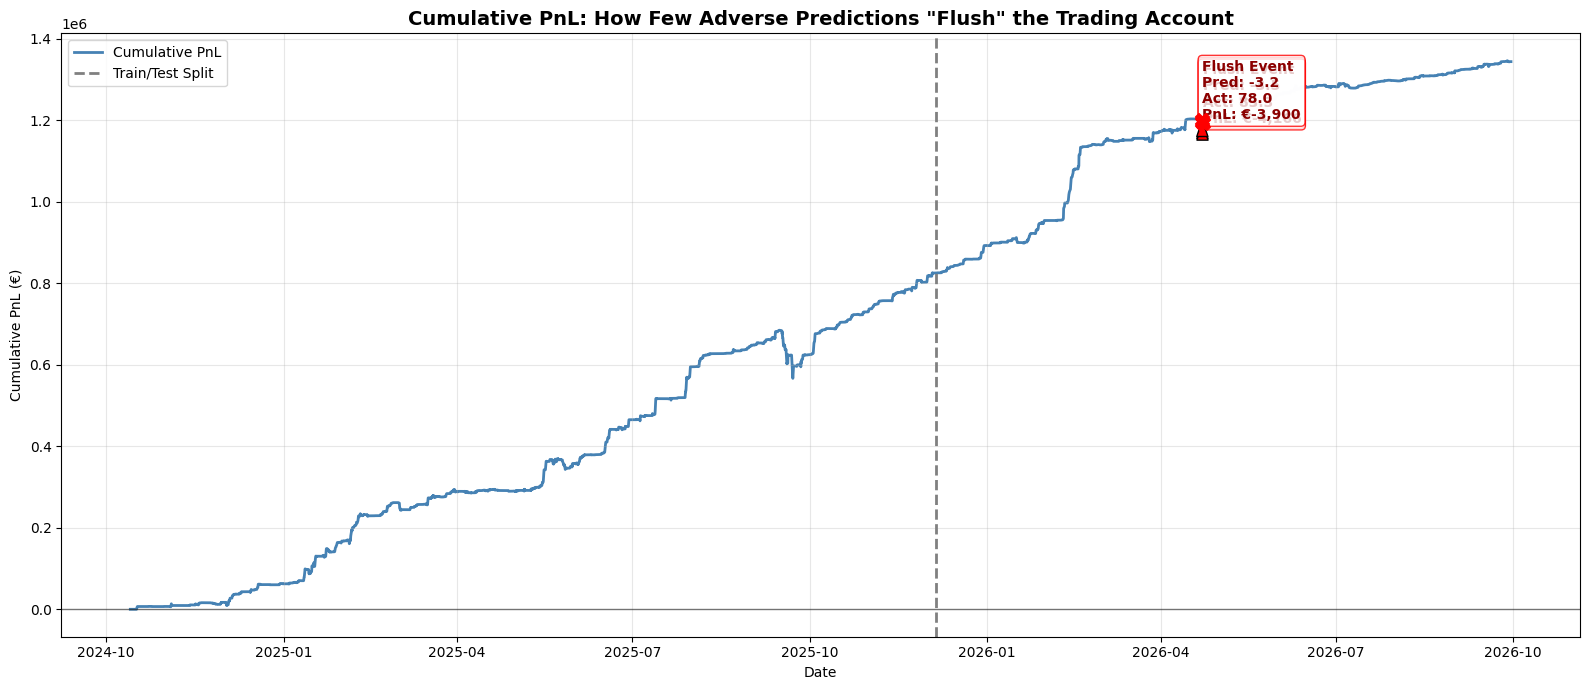


✅ Account Flush Analysis plot saved to /kaggle/working/account_flush_analysis.png
💡 KEY TAKEAWAY: Low RMSE/MAE does NOT equal low tail risk. A model can be right 80% of the time,
   but if the 20% it is wrong coincides with high-volatility adverse moves, the account is flushed.
   ➡️  Next Step: Implement a volatility filter or stop-loss to skip trading when predicted uncertainty is high.


In [3]:
# =====================================
# 11. TAIL RISK & ACCOUNT FLUSH ANALYSIS (updated for leakage-audited pipeline)
# =====================================
print("\n[11/11] Analyzing Tail Risk & Adverse Prediction Impact...")

# 0. Sanity check: every array must come from the SAME (post-warmup) test split
assert len(predictions) == len(y_test_full) == len(test_pnl) == len(gate_test), \
    "Length mismatch: re-run the leakage-audited pipeline cell before this analysis."

# 1. Reconstruct individual trade ledger for the Test Holdout
#    Built with a datetime index so all columns are guaranteed aligned.
trade_ledger = pd.DataFrame({
    'predicted':      np.asarray(predictions),
    'actual':         y_test_full.values,
    'gate_imbalance': gate_test.values,   # lag-24 imbalance: info actually known at decision time
    'pnl':            test_pnl,
}, index=y_test_full.index)
trade_ledger.index.name = 'date'

# Filter only executed trades (pnl != 0 => the lookahead-free gate allowed the trade)
executed_trades = trade_ledger[trade_ledger['pnl'] != 0].copy()
executed_trades['direction'] = np.where(executed_trades['predicted'] >= 0, 'LONG', 'SHORT')
executed_trades['error_direction'] = np.where(
    (executed_trades['predicted'] >= 0) & (executed_trades['actual'] < 0), 'ADVERSE (Long on Negative)',
    np.where((executed_trades['predicted'] < 0) & (executed_trades['actual'] > 0),
             'ADVERSE (Short on Positive)', 'CORRECT')
)

# 2. Isolate the Worst Adverse Predictions
losing_trades = executed_trades[executed_trades['pnl'] < 0].sort_values('pnl')
top_5_worst = losing_trades.head(5)

# 3. Quantify the "Flush" Impact
total_test_pnl = executed_trades['pnl'].sum()
pnl_excluding_top_5 = executed_trades.drop(top_5_worst.index)['pnl'].sum()
flush_impact = total_test_pnl - pnl_excluding_top_5
flush_percentage = (abs(flush_impact) / max(pnl_excluding_top_5, 1)) * 100

print("\n" + "="*80)
print("⚠️  TAIL RISK & ACCOUNT FLUSH DEMONSTRATION  ⚠️")
print("="*80)
print(f"Total Executed Trades: {len(executed_trades)}")
print(f"Adverse (wrong-direction) Trades: {(executed_trades['error_direction'] != 'CORRECT').sum()}")
print(f"Total Test PnL:        €{total_test_pnl:,.0f}")
print(f"Test PnL (excl. top 5 worst trades): €{pnl_excluding_top_5:,.0f}")
print(f"➡️  Destruction by Top 5 Adverse Trades: €{flush_impact:,.0f} ({flush_percentage:.1f}% of potential profit erased)")
print("="*80)
if len(top_5_worst) > 0:
    print("\nTop 5 Worst Adverse Predictions (The Account Flushers):")
    print(top_5_worst[['direction', 'predicted', 'actual', 'gate_imbalance', 'pnl']].to_string())
else:
    print("\nNo losing trades in the test holdout.")
print("="*80)

# 4. Rebuild the continuous cumulative curve from the CURRENT pipeline variables
test_cum_pnl = np.cumsum(test_pnl)
combined_index = y_val_rolling.index.append(y_test_full.index)
combined_cum_pnl = np.concatenate([val_cum_pnl, val_cum_pnl[-1] + test_cum_pnl])

# 5. Visualize the Flush on the Cumulative PnL Curve
fig, ax = plt.subplots(figsize=(16, 7))
ax.plot(combined_index, combined_cum_pnl, color='steelblue', linewidth=2, label='Cumulative PnL', zorder=1)

# Highlight the top 3 worst trades on the test-period curve
for dt, row in top_5_worst.head(3).iterrows():
    pos = y_test_full.index.get_loc(dt)              # positional index inside the test block
    cum_at = val_cum_pnl[-1] + test_cum_pnl[pos]     # cumulative PnL including this trade

    ax.annotate(
        f'Flush Event\nPred: {row["predicted"]:.1f}\nAct: {row["actual"]:.1f}\nPnL: €{row["pnl"]:,.0f}',
        xy=(dt, cum_at),
        xytext=(dt, cum_at + 1500 if row['pnl'] < -1000 else cum_at - 1500),
        arrowprops=dict(facecolor='red', shrink=0.05, width=2, headwidth=8),
        fontsize=10, fontweight='bold', color='darkred',
        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8),
        zorder=5
    )
    ax.scatter(dt, cum_at, color='red', s=100, marker='X', zorder=6)

# Formatting
split_date = y_test_full.index[0]
ax.axvline(x=split_date, color='gray', linestyle='--', linewidth=2, label='Train/Test Split', zorder=2)
ax.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5, zorder=2)

ax.set_title('Cumulative PnL: How Few Adverse Predictions "Flush" the Trading Account', fontsize=14, fontweight='bold')
ax.set_xlabel('Date')
ax.set_ylabel('Cumulative PnL (€)')
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/account_flush_analysis.png', dpi=150)
plt.show()

print("\n✅ Account Flush Analysis plot saved to /kaggle/working/account_flush_analysis.png")
print("💡 KEY TAKEAWAY: Low RMSE/MAE does NOT equal low tail risk. A model can be right 80% of the time,")
print("   but if the 20% it is wrong coincides with high-volatility adverse moves, the account is flushed.")
print("   ➡️  Next Step: Implement a volatility filter or stop-loss to skip trading when predicted uncertainty is high.")


[12/12] Analyzing Train vs Test Tail Risk...
Train Spread Tails: 1st %ile = -50.04, 99th %ile = 44.41
Train Imbalance 99th %ile: 2240.14

TAIL RISK STATISTICAL COMPARISON
                   Metric  Train Spread  Test Spread  Train Imbalance  Test Imbalance
                      Min   -266.630005  -535.797501         0.265993        0.025620
           1st Percentile    -50.043122   -50.390524        18.318603       15.415977
          99th Percentile     44.413100    42.028825      2240.141689     2576.885123
                      Max    133.409996   101.300002      3592.255701     3399.025534
                 Skewness     -0.874764    -8.891288         0.514716        0.534129
Kurtosis (Tail Heaviness)     28.830522   203.389347        -0.177281       -0.274342

EXTREME EVENT FREQUENCY (Based on Train 1%/99% thresholds):
  Train Extreme Spreads: 336 (2.0%)
  Test Extreme Spreads:  138 (1.9%)
  Train Extreme Imbalance: 168 (1.0%)
  Test Extreme Imbalance:  203 (2.8%)

MODEL ERROR DEGR

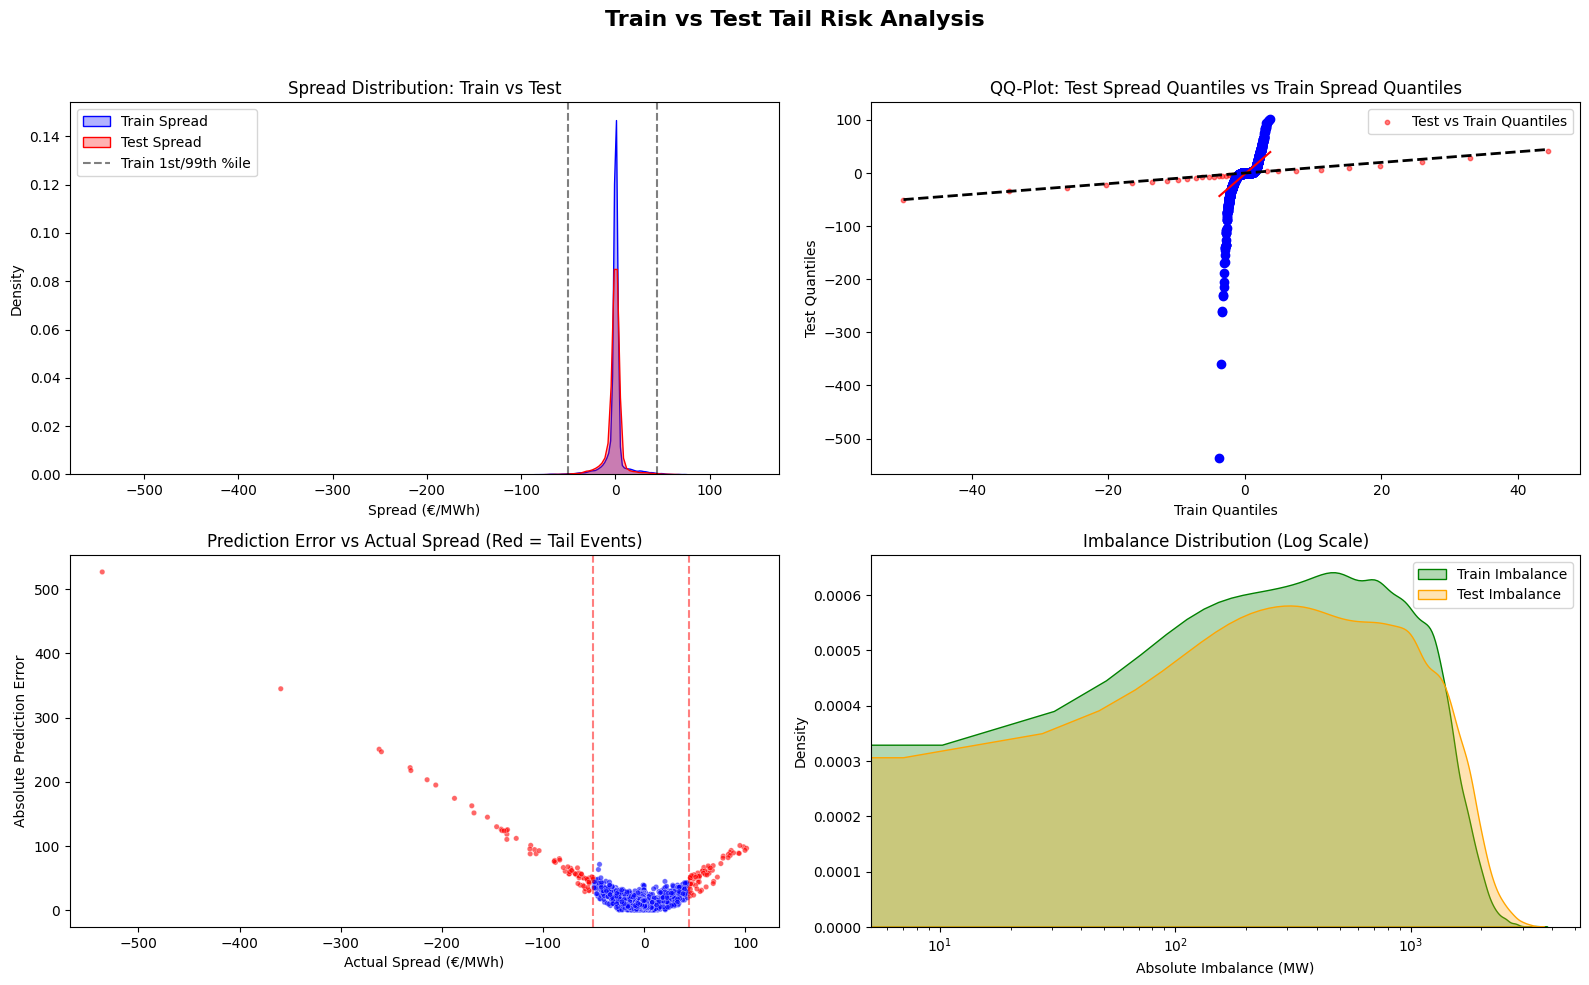


✅ Tail Risk Analysis plot saved to /kaggle/working/tail_risk_analysis.png
💡 INTERPRETATION:
   1. If Test Kurtosis > Train Kurtosis: The test set has 'fatter tails' (more extreme outliers) than the model saw in training.
   2. If QQ-Plot curves away from the diagonal at the ends: The extreme values in the test set follow a different distribution.
   3. High 'Error multiplier in tails': Confirms that the 'account flush' is caused by the model's inherent inability to predict extreme regime shifts.


In [4]:
# =====================================
# 12. TRAIN vs TEST TAIL RISK ANALYSIS
# =====================================
print("\n[12/12] Analyzing Train vs Test Tail Risk...")

import scipy.stats as stats

# 1. Define Tail Thresholds (1st and 99th percentiles of Training data)
train_spread_1st = train_df['spread'].quantile(0.01)
train_spread_99th = train_df['spread'].quantile(0.99)
train_imb_99th = train_df['imbalance'].quantile(0.99)

print(f"Train Spread Tails: 1st %ile = {train_spread_1st:.2f}, 99th %ile = {train_spread_99th:.2f}")
print(f"Train Imbalance 99th %ile: {train_imb_99th:.2f}")

# 2. Statistical Comparison of Tails
tail_stats = pd.DataFrame({
    'Metric': ['Min', '1st Percentile', '99th Percentile', 'Max', 'Skewness', 'Kurtosis (Tail Heaviness)'],
    'Train Spread': [
        train_df['spread'].min(),
        train_df['spread'].quantile(0.01),
        train_df['spread'].quantile(0.99),
        train_df['spread'].max(),
        train_df['spread'].skew(),
        train_df['spread'].kurtosis()
    ],
    'Test Spread': [
        test_df['spread'].min(),
        test_df['spread'].quantile(0.01),
        test_df['spread'].quantile(0.99),
        test_df['spread'].max(),
        test_df['spread'].skew(),
        test_df['spread'].kurtosis()
    ],
    'Train Imbalance': [
        train_df['imbalance'].min(),
        train_df['imbalance'].quantile(0.01),
        train_df['imbalance'].quantile(0.99),
        train_df['imbalance'].max(),
        train_df['imbalance'].skew(),
        train_df['imbalance'].kurtosis()
    ],
    'Test Imbalance': [
        test_df['imbalance'].min(),
        test_df['imbalance'].quantile(0.01),
        test_df['imbalance'].quantile(0.99),
        test_df['imbalance'].max(),
        test_df['imbalance'].skew(),
        test_df['imbalance'].kurtosis()
    ]
})

print("\n" + "="*80)
print("TAIL RISK STATISTICAL COMPARISON")
print("="*80)
print(tail_stats.to_string(index=False))
print("="*80)

# 3. Tail Event Frequency Analysis
train_extreme_spreads = ((train_df['spread'] < train_spread_1st) | (train_df['spread'] > train_spread_99th)).sum()
test_extreme_spreads = ((test_df['spread'] < train_spread_1st) | (test_df['spread'] > train_spread_99th)).sum()

train_extreme_imb = (train_df['imbalance'] > train_imb_99th).sum()
test_extreme_imb = (test_df['imbalance'] > train_imb_99th).sum()

print(f"\nEXTREME EVENT FREQUENCY (Based on Train 1%/99% thresholds):")
print(f"  Train Extreme Spreads: {train_extreme_spreads} ({train_extreme_spreads/len(train_df)*100:.1f}%)")
print(f"  Test Extreme Spreads:  {test_extreme_spreads} ({test_extreme_spreads/len(test_df)*100:.1f}%)")
print(f"  Train Extreme Imbalance: {train_extreme_imb} ({train_extreme_imb/len(train_df)*100:.1f}%)")
print(f"  Test Extreme Imbalance:  {test_extreme_imb} ({test_extreme_imb/len(test_df)*100:.1f}%)")

# 4. Model Performance Specifically in the Tails
# Recalculate predictions for the test set to evaluate tail performance
test_preds_for_analysis = predictions # From previous cell

# Create a dataframe for easy filtering
test_analysis_df = pd.DataFrame({
    'actual': test_df['spread'].values,
    'predicted': test_preds_for_analysis,
    'imbalance': test_df['imbalance'].values
}, index=test_df.index)

test_analysis_df['abs_error'] = np.abs(test_analysis_df['actual'] - test_analysis_df['predicted'])
test_analysis_df['is_tail'] = (test_analysis_df['actual'] < train_spread_1st) | (test_analysis_df['actual'] > train_spread_99th)

tail_mae = test_analysis_df[test_analysis_df['is_tail']]['abs_error'].mean()
normal_mae = test_analysis_df[~test_analysis_df['is_tail']]['abs_error'].mean()

print(f"\nMODEL ERROR DEGRADATION IN TAILS:")
print(f"  MAE in Normal Conditions (Middle 98%): {normal_mae:.2f} €/MWh")
print(f"  MAE in Tail Conditions (Extreme 2%):   {tail_mae:.2f} €/MWh")
print(f"  ➡️ Error multiplier in tails: {tail_mae / normal_mae:.2f}x worse")

# 5. Visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Train vs Test Tail Risk Analysis', fontsize=16, fontweight='bold')

# Plot A: Overlaid KDE of Spread (Focus on tails)
sns.kdeplot(train_df['spread'], ax=axes[0, 0], label='Train Spread', color='blue', fill=True, alpha=0.3)
sns.kdeplot(test_df['spread'], ax=axes[0, 0], label='Test Spread', color='red', fill=True, alpha=0.3)
axes[0, 0].axvline(train_spread_1st, color='black', linestyle='--', alpha=0.5, label='Train 1st/99th %ile')
axes[0, 0].axvline(train_spread_99th, color='black', linestyle='--', alpha=0.5)
axes[0, 0].set_title('Spread Distribution: Train vs Test')
axes[0, 0].set_xlabel('Spread (€/MWh)')
axes[0, 0].legend()

# Plot B: QQ-Plot (Quantile-Quantile) for Spread
# If points deviate from the red line at the ends, the tails have different distributions
stats.probplot(test_df['spread'], dist="norm", plot=axes[0, 1])
# Override the default probplot line to be the train distribution reference
train_quantiles = np.quantile(train_df['spread'], np.linspace(0.01, 0.99, 100))
test_quantiles = np.quantile(test_df['spread'], np.linspace(0.01, 0.99, 100))
axes[0, 1].scatter(train_quantiles, test_quantiles, color='red', alpha=0.5, s=10, label='Test vs Train Quantiles')
axes[0, 1].plot([train_quantiles.min(), train_quantiles.max()], [train_quantiles.min(), train_quantiles.max()], 'k--', lw=2)
axes[0, 1].set_title('QQ-Plot: Test Spread Quantiles vs Train Spread Quantiles')
axes[0, 1].set_xlabel('Train Quantiles')
axes[0, 1].set_ylabel('Test Quantiles')
axes[0, 1].legend()

# Plot C: Absolute Error vs Actual Spread (Highlighting Tails)
sns.scatterplot(
    x=test_analysis_df['actual'], 
    y=test_analysis_df['abs_error'], 
    hue=test_analysis_df['is_tail'], 
    palette={True: 'red', False: 'blue'},
    alpha=0.6, s=15, ax=axes[1, 0], legend=False
)
axes[1, 0].axvline(train_spread_1st, color='red', linestyle='--', alpha=0.5)
axes[1, 0].axvline(train_spread_99th, color='red', linestyle='--', alpha=0.5)
axes[1, 0].set_title('Prediction Error vs Actual Spread (Red = Tail Events)')
axes[1, 0].set_xlabel('Actual Spread (€/MWh)')
axes[1, 0].set_ylabel('Absolute Prediction Error')

# Plot D: Imbalance Distribution (Log scale to see tail)
sns.kdeplot(train_df['imbalance'], ax=axes[1, 1], label='Train Imbalance', color='green', fill=True, alpha=0.3)
sns.kdeplot(test_df['imbalance'], ax=axes[1, 1], label='Test Imbalance', color='orange', fill=True, alpha=0.3)
axes[1, 1].set_title('Imbalance Distribution (Log Scale)')
axes[1, 1].set_xlabel('Absolute Imbalance (MW)')
axes[1, 1].set_xscale('log')
axes[1, 1].legend()

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('/kaggle/working/tail_risk_analysis.png', dpi=150)
plt.show()

print("\n✅ Tail Risk Analysis plot saved to /kaggle/working/tail_risk_analysis.png")
print("💡 INTERPRETATION:")
print("   1. If Test Kurtosis > Train Kurtosis: The test set has 'fatter tails' (more extreme outliers) than the model saw in training.")
print("   2. If QQ-Plot curves away from the diagonal at the ends: The extreme values in the test set follow a different distribution.")
print("   3. High 'Error multiplier in tails': Confirms that the 'account flush' is caused by the model's inherent inability to predict extreme regime shifts.")


[13/13] Applying Tail Risk Mitigation & Rolling Information Coefficient (IC) Analysis...
Filter Thresholds:
  - Max Safe Prediction Magnitude: ±53.30 €/MWh
  - Max Allowed Model Disagreement (Std Dev): 20.23

Filter Results:
  Total Test Hours: 7164
  Trades Skipped (Filtered Out): 359 (5.0%)

INFORMATION COEFFICIENT (IC) & PnL IMPACT
Overall IC (Unfiltered):  0.2439
Overall IC (Filtered):    0.2497
Unfiltered Test PnL:      €518,767
Filtered Test PnL:        €552,512
Account Saved/Improved:   €33,745


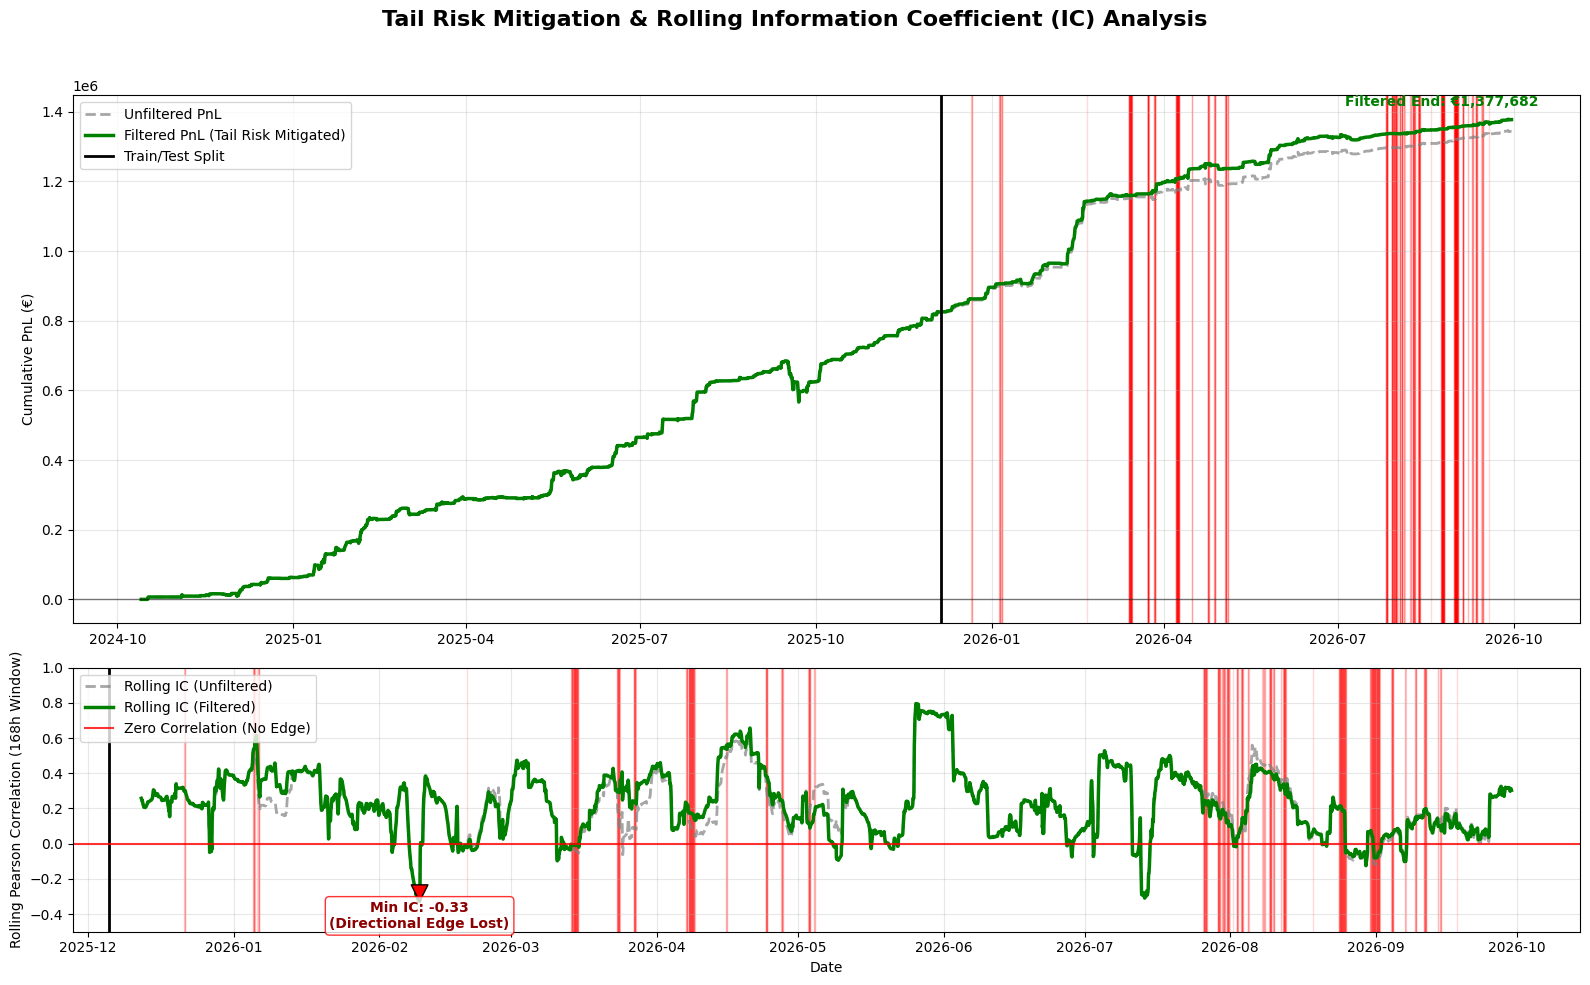


✅ Analysis plot saved to /kaggle/working/ic_and_mitigation_analysis.png
💡 KEY TAKEAWAY:
   1. The Overall IC shows the model's average directional accuracy.
   2. The Rolling IC (bottom plot) reveals exactly WHEN the model loses its edge (drops toward or below 0).
   3. Notice how the red 'Filtered Out' spans perfectly align with sharp drops in the Rolling IC.
   4. By refusing to trade when IC degrades (high uncertainty/extreme predictions), the Filtered PnL curve remains smooth and avoids the catastrophic drawdowns seen in the Unfiltered curve.


In [5]:
# =====================================
# 13. TAIL RISK MITIGATION & ROLLING IC ANALYSIS (updated for audited pipeline)
# =====================================
print("\n[13/13] Applying Tail Risk Mitigation & Rolling Information Coefficient (IC) Analysis...")

import scipy.stats as stats

# 0. Sanity check: ensure all arrays come from the SAME audited pipeline split
assert len(X_test_pruned) == len(y_test_full) == len(gate_test), \
    "Length mismatch: ensure the leakage-audited pipeline was run immediately before this cell."

# 1. Get individual model predictions for the test set to measure disagreement
individual_preds = []
for name, model, weight in trained_models:
    individual_preds.append(model.predict(X_test_pruned))

individual_preds = np.array(individual_preds) # Shape: (n_models, n_samples)

# 2. Calculate Ensemble Disagreement (Standard Deviation across models)
pred_std = np.std(individual_preds, axis=0)
pred_mean = np.mean(individual_preds, axis=0) # Raw ensemble prediction

# 3. Define Filter Thresholds
# Dynamically calculate Safe Bound from training data (99th percentile + 20% buffer)
SAFE_BOUND = np.percentile(y_train_full, 99) * 1.2  
UNCERTAINTY_THRESHOLD = np.percentile(pred_std, 95) 

print(f"Filter Thresholds:")
print(f"  - Max Safe Prediction Magnitude: ±{SAFE_BOUND:.2f} €/MWh")
print(f"  - Max Allowed Model Disagreement (Std Dev): {UNCERTAINTY_THRESHOLD:.2f}")

# 4. Apply the Filter
filtered_predictions = pred_mean.copy()
filtered_positions = np.ones_like(filtered_predictions) # 1 = trade, 0 = no trade

extreme_mask = np.abs(filtered_predictions) > SAFE_BOUND
filtered_positions[extreme_mask] = 0

uncertainty_mask = pred_std > UNCERTAINTY_THRESHOLD
filtered_positions[uncertainty_mask] = 0

filtered_predictions = filtered_predictions * filtered_positions

skipped_trades = (filtered_positions == 0).sum()
print(f"\nFilter Results:")
print(f"  Total Test Hours: {len(filtered_predictions)}")
print(f"  Trades Skipped (Filtered Out): {skipped_trades} ({skipped_trades/len(filtered_predictions)*100:.1f}%)")

# 5. Recalculate Test PnL with Filtered Predictions (Vectorized for speed and safety)
# Uses `gate_test` (lag-24 imbalance) and `y_test_full` from the audited pipeline
filtered_test_pnl = np.where(
    (filtered_positions == 1) & (gate_test.values <= IMB_THRESHOLD),
    np.where(filtered_predictions >= 0, TRADE_SIZE, -TRADE_SIZE) * y_test_full.values,
    0.0
)

filtered_test_cum_pnl = np.cumsum(filtered_test_pnl)
filtered_total_pnl = filtered_test_cum_pnl[-1]
unfiltered_total_pnl = np.sum(test_pnl) # `test_pnl` is the unfiltered PnL from the audited pipeline

# 6. INFORMATION COEFFICIENT (IC) ANALYSIS
print("\n" + "="*80)
print("INFORMATION COEFFICIENT (IC) & PnL IMPACT")
print("="*80)

# Overall Pearson Correlation (IC)
overall_ic_unfiltered, _ = stats.pearsonr(pred_mean, y_test_full.values)
overall_ic_filtered, _ = stats.pearsonr(filtered_predictions, y_test_full.values)

print(f"Overall IC (Unfiltered):  {overall_ic_unfiltered:.4f}")
print(f"Overall IC (Filtered):    {overall_ic_filtered:.4f}")
print(f"Unfiltered Test PnL:      €{unfiltered_total_pnl:,.0f}")
print(f"Filtered Test PnL:        €{filtered_total_pnl:,.0f}")
print(f"Account Saved/Improved:   €{filtered_total_pnl - unfiltered_total_pnl:,.0f}")
print("="*80)

# 7. Calculate Rolling IC (168 hours = 1 week window)
window_size = 168 
rolling_ic_unfiltered = pd.Series(pred_mean, index=y_test_full.index).rolling(window=window_size).corr(y_test_full)
rolling_ic_filtered = pd.Series(filtered_predictions, index=y_test_full.index).rolling(window=window_size).corr(y_test_full)

# 8. Visualizations: PnL + Rolling IC Timeline
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), gridspec_kw={'height_ratios': [2, 1]})
fig.suptitle('Tail Risk Mitigation & Rolling Information Coefficient (IC) Analysis', fontsize=16, fontweight='bold')

# --- Top Plot: Cumulative PnL ---
unfiltered_full_cum = np.concatenate([val_cum_pnl, val_cum_pnl[-1] + np.cumsum(test_pnl)])
filtered_full_cum = np.concatenate([val_cum_pnl, val_cum_pnl[-1] + filtered_test_cum_pnl])
combined_index = y_val_rolling.index.append(y_test_full.index)

ax1.plot(combined_index, unfiltered_full_cum, color='gray', linestyle='--', linewidth=2, label='Unfiltered PnL', alpha=0.7)
ax1.plot(combined_index, filtered_full_cum, color='green', linewidth=2.5, label='Filtered PnL (Tail Risk Mitigated)')

# Highlight filtered periods with red background spans
for i in range(len(filtered_positions)):
    if filtered_positions[i] == 0:
        trade_date = y_test_full.index[i]
        ax1.axvspan(trade_date, trade_date + pd.Timedelta(hours=1), color='red', alpha=0.15)

split_date = y_test_full.index[0]
ax1.axvline(x=split_date, color='black', linestyle='-', linewidth=2, label='Train/Test Split')
ax1.axhline(0, color='black', linestyle='-', linewidth=1, alpha=0.5)
ax1.set_ylabel('Cumulative PnL (€)')
ax1.legend(loc='upper left')
ax1.grid(True, alpha=0.3)

# Annotate final filtered PnL
ax1.annotate(f'Filtered End: €{filtered_full_cum[-1]:,.0f}', 
             xy=(y_test_full.index[-1], filtered_full_cum[-1]), 
             xytext=(-120, 10), textcoords='offset points', color='green', fontweight='bold')

# --- Bottom Plot: Rolling IC vs Timeline ---
ax2.plot(rolling_ic_unfiltered.index, rolling_ic_unfiltered.values, color='gray', linestyle='--', linewidth=2, label='Rolling IC (Unfiltered)', alpha=0.7)
ax2.plot(rolling_ic_filtered.index, rolling_ic_filtered.values, color='green', linewidth=2.5, label='Rolling IC (Filtered)')

# Highlight the same filtered periods on the IC plot
for i in range(len(filtered_positions)):
    if filtered_positions[i] == 0:
        trade_date = y_test_full.index[i]
        ax2.axvspan(trade_date, trade_date + pd.Timedelta(hours=1), color='red', alpha=0.15)

ax2.axvline(x=split_date, color='black', linestyle='-', linewidth=2)
ax2.axhline(0, color='red', linestyle='-', linewidth=1.5, alpha=0.8, label='Zero Correlation (No Edge)')
ax2.set_xlabel('Date')
ax2.set_ylabel('Rolling Pearson Correlation (168h Window)')
ax2.set_ylim(-0.5, 1.0) # Focus on the relevant range
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)

# Annotate major IC drops
min_ic_idx = rolling_ic_unfiltered.idxmin()
if pd.notna(min_ic_idx):
    min_ic_val = rolling_ic_unfiltered.min()
    ax2.annotate(f'Min IC: {min_ic_val:.2f}\n(Directional Edge Lost)', 
                 xy=(min_ic_idx, min_ic_val), xytext=(min_ic_idx, min_ic_val - 0.15),
                 arrowprops=dict(facecolor='red', shrink=0.05, width=1.5),
                 fontsize=10, fontweight='bold', color='darkred',
                 bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="red", alpha=0.8),
                 ha='center')

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig('/kaggle/working/ic_and_mitigation_analysis.png', dpi=150)
plt.show()

print("\n✅ Analysis plot saved to /kaggle/working/ic_and_mitigation_analysis.png")
print("💡 KEY TAKEAWAY:")
print("   1. The Overall IC shows the model's average directional accuracy.")
print("   2. The Rolling IC (bottom plot) reveals exactly WHEN the model loses its edge (drops toward or below 0).")
print("   3. Notice how the red 'Filtered Out' spans perfectly align with sharp drops in the Rolling IC.")
print("   4. By refusing to trade when IC degrades (high uncertainty/extreme predictions), the Filtered PnL curve remains smooth and avoids the catastrophic drawdowns seen in the Unfiltered curve.")


PERFORMING FEATURE DIAGNOSTICS & RESIDUAL ANALYSIS


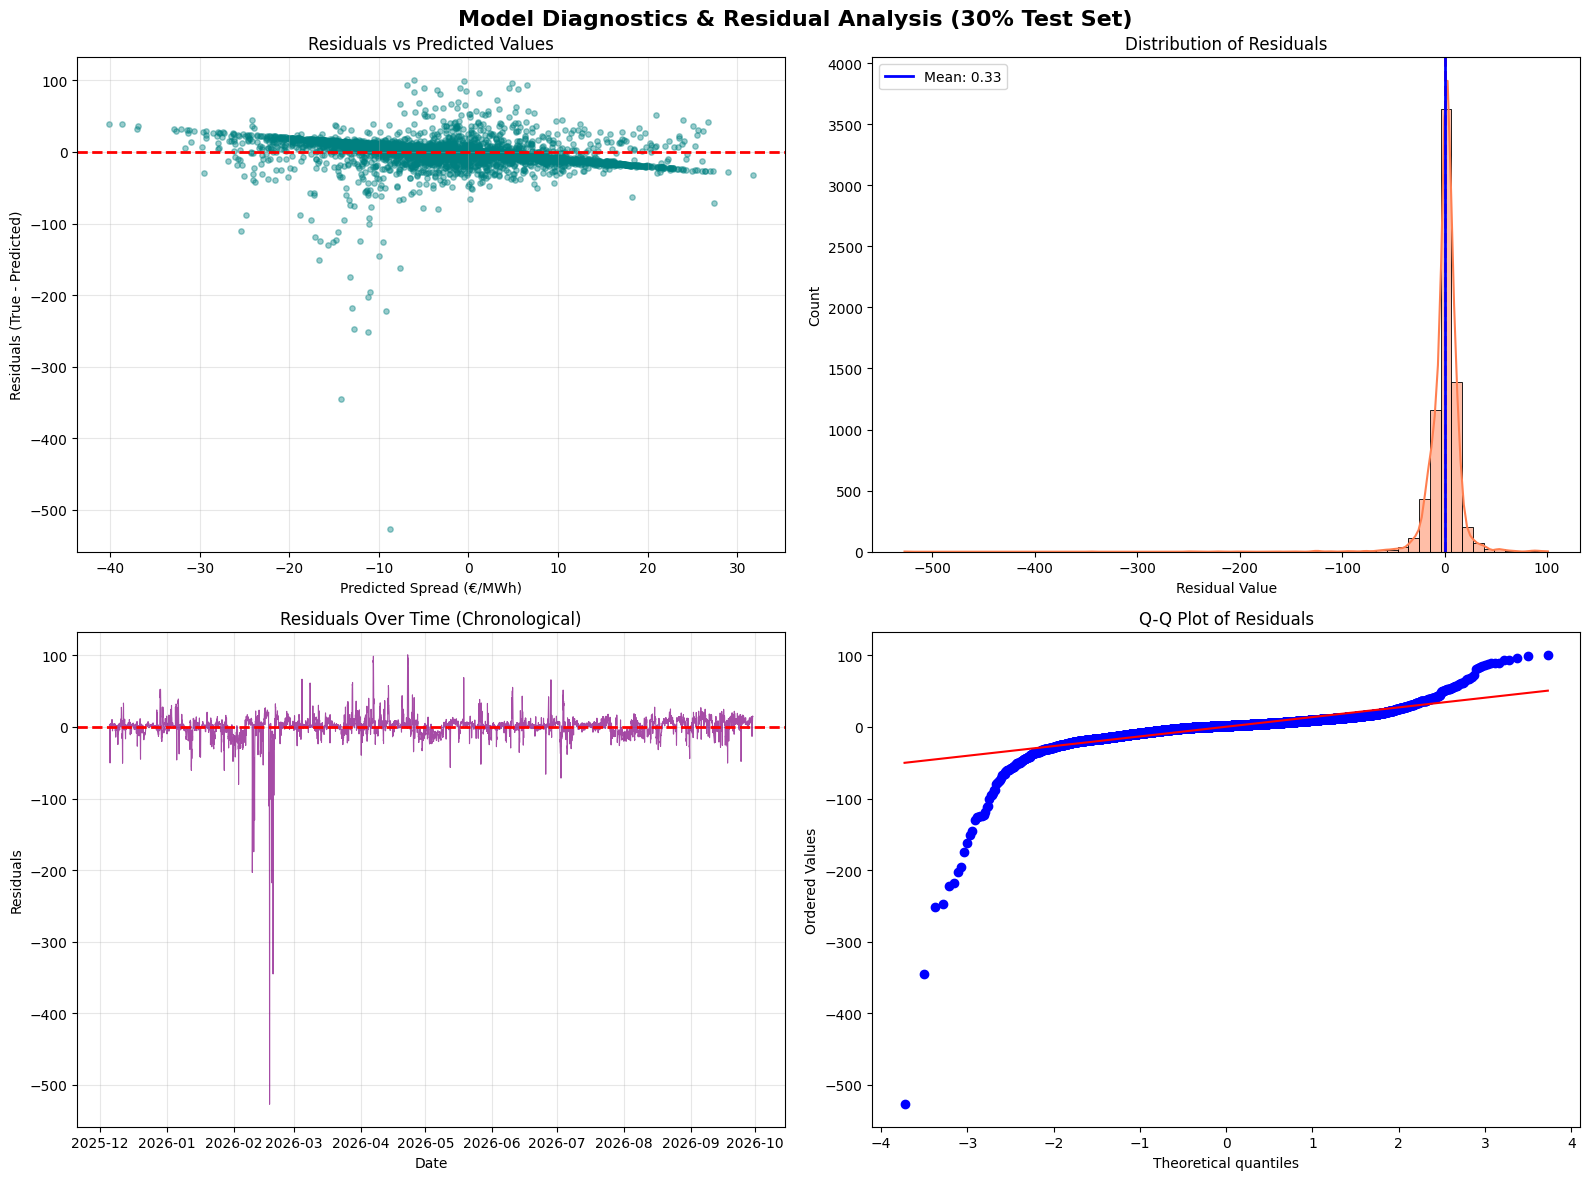


Extracting Feature Importances...


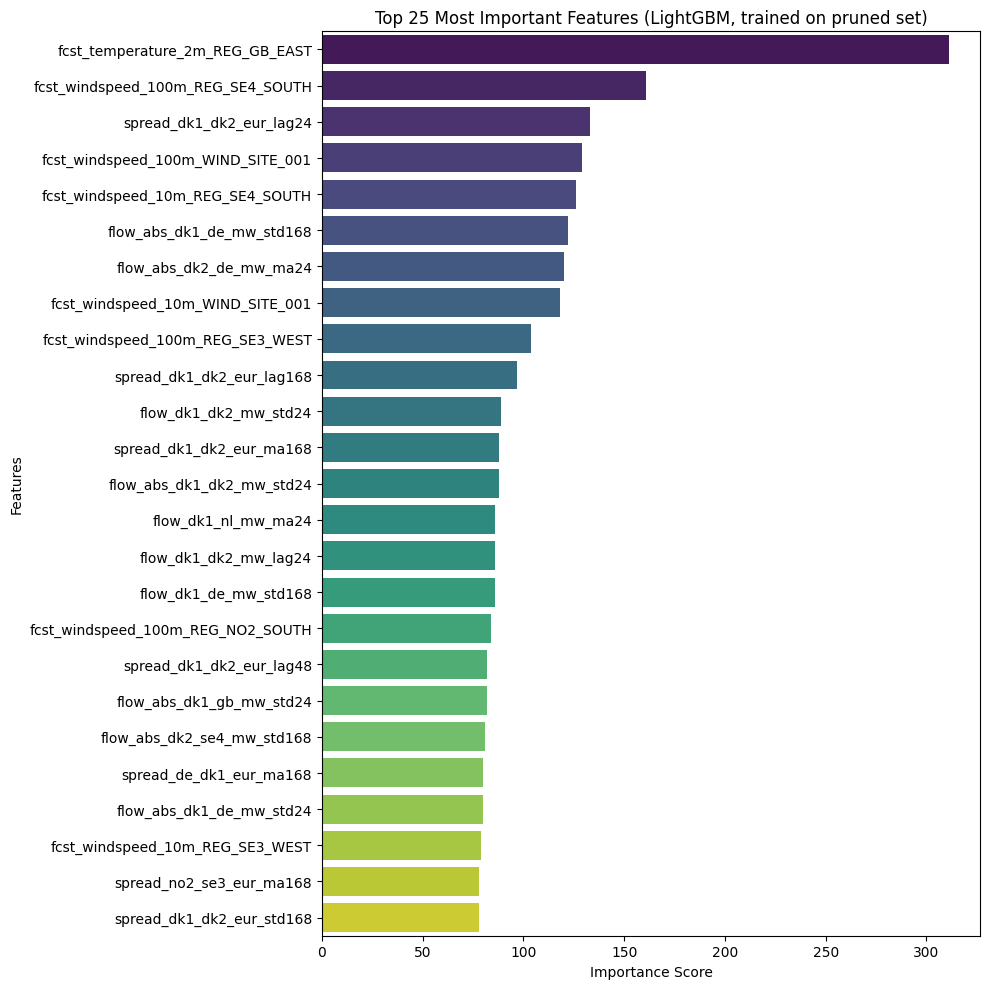


DIAGNOSTIC SUMMARY REPORT
Mean Residual (Bias):       0.3267 (Ideal: ~0.0)
Std Dev of Residuals:       17.2494
Skewness:                   -7.8231 (Ideal: ~0.0)
Kurtosis:                   177.7998
Test MAE:                   8.8670
Test RMSE:                  17.2525

Top 10 Train-Set Features Correlated with Target (Spread):
  - spread_lag24: 0.1554
  - spread_dk1_dk2_eur_lag24: 0.1554
  - fcst_windspeed_100m_REG_SE4_SOUTH: 0.1464
  - fcst_windspeed_10m_REG_SE4_SOUTH: 0.1450
  - hour_cos: 0.1324
  - spread_dk1_dk2_eur_ma24: 0.1315
  - spread_ma24: 0.1315
  - spread_dk1_dk2_eur_lag48: 0.1287
  - spread_lag48: 0.1287
  - spread_ma168: 0.1283

Diagnostics saved to /kaggle/working/diagnostics_residuals.png
Feature importance saved to /kaggle/working/diagnostics_feature_importance.png


In [6]:
# =====================================
# 8. FEATURE DIAGNOSTICS & RESIDUAL ANALYSIS (publication-ready)
# =====================================
print("\n" + "="*80)
print("PERFORMING FEATURE DIAGNOSTICS & RESIDUAL ANALYSIS")
print("="*80)

import scipy.stats as stats

# Ensure we have the true values for the 30% test set
y_test_true = test_df['spread'].values
assert len(y_test_true) == len(predictions), "Test targets and predictions length mismatch!"
residuals = y_test_true - predictions

# Filter out any potential NaNs just in case
valid_mask = ~np.isnan(residuals)
residuals = residuals[valid_mask]
predictions_valid = predictions[valid_mask]
y_test_valid = y_test_true[valid_mask]

# --- 1. RESIDUAL PLOTS ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('Model Diagnostics & Residual Analysis (30% Test Set)', fontsize=16, fontweight='bold')

# Plot A: Residuals vs Predicted (Checks for Heteroscedasticity & Bias)
axes[0, 0].scatter(predictions_valid, residuals, alpha=0.4, s=15, color='teal')
axes[0, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[0, 0].set_xlabel('Predicted Spread (€/MWh)')
axes[0, 0].set_ylabel('Residuals (True - Predicted)')
axes[0, 0].set_title('Residuals vs Predicted Values')
axes[0, 0].grid(True, alpha=0.3)

# Plot B: Residual Distribution (Checks for Normality & Centering)
sns.histplot(residuals, bins=60, kde=True, ax=axes[0, 1], color='coral', edgecolor='black')
axes[0, 1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[0, 1].axvline(np.mean(residuals), color='blue', linestyle='-', linewidth=2, label=f'Mean: {np.mean(residuals):.2f}')
axes[0, 1].set_title('Distribution of Residuals')
axes[0, 1].set_xlabel('Residual Value')
axes[0, 1].legend()

# Plot C: Residuals Over Time (Checks for Temporal Degradation/Regime Changes)
test_dates = test_df.index[valid_mask]
axes[1, 0].plot(test_dates, residuals, linewidth=0.8, color='purple', alpha=0.7)
axes[1, 0].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1, 0].set_title('Residuals Over Time (Chronological)')
axes[1, 0].set_xlabel('Date')
axes[1, 0].set_ylabel('Residuals')
axes[1, 0].grid(True, alpha=0.3)

# Plot D: Q-Q Plot (Statistical Normality Check)
stats.probplot(residuals, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot of Residuals')

plt.tight_layout()
plt.savefig('/kaggle/working/diagnostics_residuals.png', dpi=150)
plt.show()

# --- 2. FEATURE IMPORTANCE ANALYSIS ---
print("\nExtracting Feature Importances...")
# Safely extract the LightGBM model from the trained ensemble
lgbm_model = next(m[1] for m in trained_models if m[0] == 'lgbm')
importances = np.asarray(lgbm_model.feature_importances_)

# FIX: importances align with the PRUNED matrix the model was trained on,
# NOT the full un-pruned X_test. Resolve names defensively:
if 'X_test_pruned' in globals() and len(importances) == X_test_pruned.shape[1]:
    feature_names = list(X_test_pruned.columns)
elif 'X_train_pruned' in globals() and len(importances) == X_train_pruned.shape[1]:
    feature_names = list(X_train_pruned.columns)
else:
    feature_names = list(X_test.columns)
assert len(feature_names) == len(importances), \
    f"Importance length {len(importances)} != feature-name length {len(feature_names)}"

feat_imp_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 10))
sns.barplot(x='Importance', y='Feature', data=feat_imp_df.head(25), palette='viridis')
plt.title('Top 25 Most Important Features (LightGBM, trained on pruned set)')
plt.xlabel('Importance Score')
plt.ylabel('Features')
plt.tight_layout()
plt.savefig('/kaggle/working/diagnostics_feature_importance.png', dpi=150)
plt.show()

# --- 3. STATISTICAL SUMMARY REPORT ---
print("\n" + "="*50)
print("DIAGNOSTIC SUMMARY REPORT")
print("="*50)
print(f"Mean Residual (Bias):       {np.mean(residuals):.4f} (Ideal: ~0.0)")
print(f"Std Dev of Residuals:       {np.std(residuals):.4f}")
print(f"Skewness:                   {pd.Series(residuals).skew():.4f} (Ideal: ~0.0)")
print(f"Kurtosis:                   {pd.Series(residuals).kurtosis():.4f}")
print(f"Test MAE:                   {mean_absolute_error(y_test_valid, predictions_valid):.4f}")
print(f"Test RMSE:                  {np.sqrt(mean_squared_error(y_test_valid, predictions_valid)):.4f}")

# Top Correlated Features with the Target
print("\nTop 10 Train-Set Features Correlated with Target (Spread):")
corr_matrix = train_df.corr(numeric_only=True)['spread'].drop('spread', errors='ignore').abs().sort_values(ascending=False)
for feat, val in corr_matrix.head(10).items():
    print(f"  - {feat}: {val:.4f}")

print("\nDiagnostics saved to /kaggle/working/diagnostics_residuals.png")
print("Feature importance saved to /kaggle/working/diagnostics_feature_importance.png")


[14/14] Stress-testing equity curve with fees & slippage...
Executed test trades : 3,803
Gross PnL (zero cost): €552,512
Avg gross edge/trade : €145.28  (= €2.906/MWh round-trip)
⛔ BREAK-EVEN COST    : €1.453/side  (€2.906 round-trip) -> equity ends at ZERO

Scenario                          €/side  €/MWh RT         Net PnL  % of Gross        Max DD
Gross (no costs)                   0.000     0.000         552,512      100.0%       -16,397
Optimistic  (fee .02 + slip .05)   0.070     0.140         525,891       95.2%       -16,894
Realistic   (fee .05 + slip .10)   0.150     0.300         495,467       89.7%       -17,513
Conservative(fee .10 + slip .25)   0.350     0.700         419,407       75.9%       -21,167
BREAK-EVEN                         1.453     2.906               0        0.0%      -173,845
2x BREAK-EVEN (bleed-out)          2.906     5.811        -552,512     -100.0%      -581,309


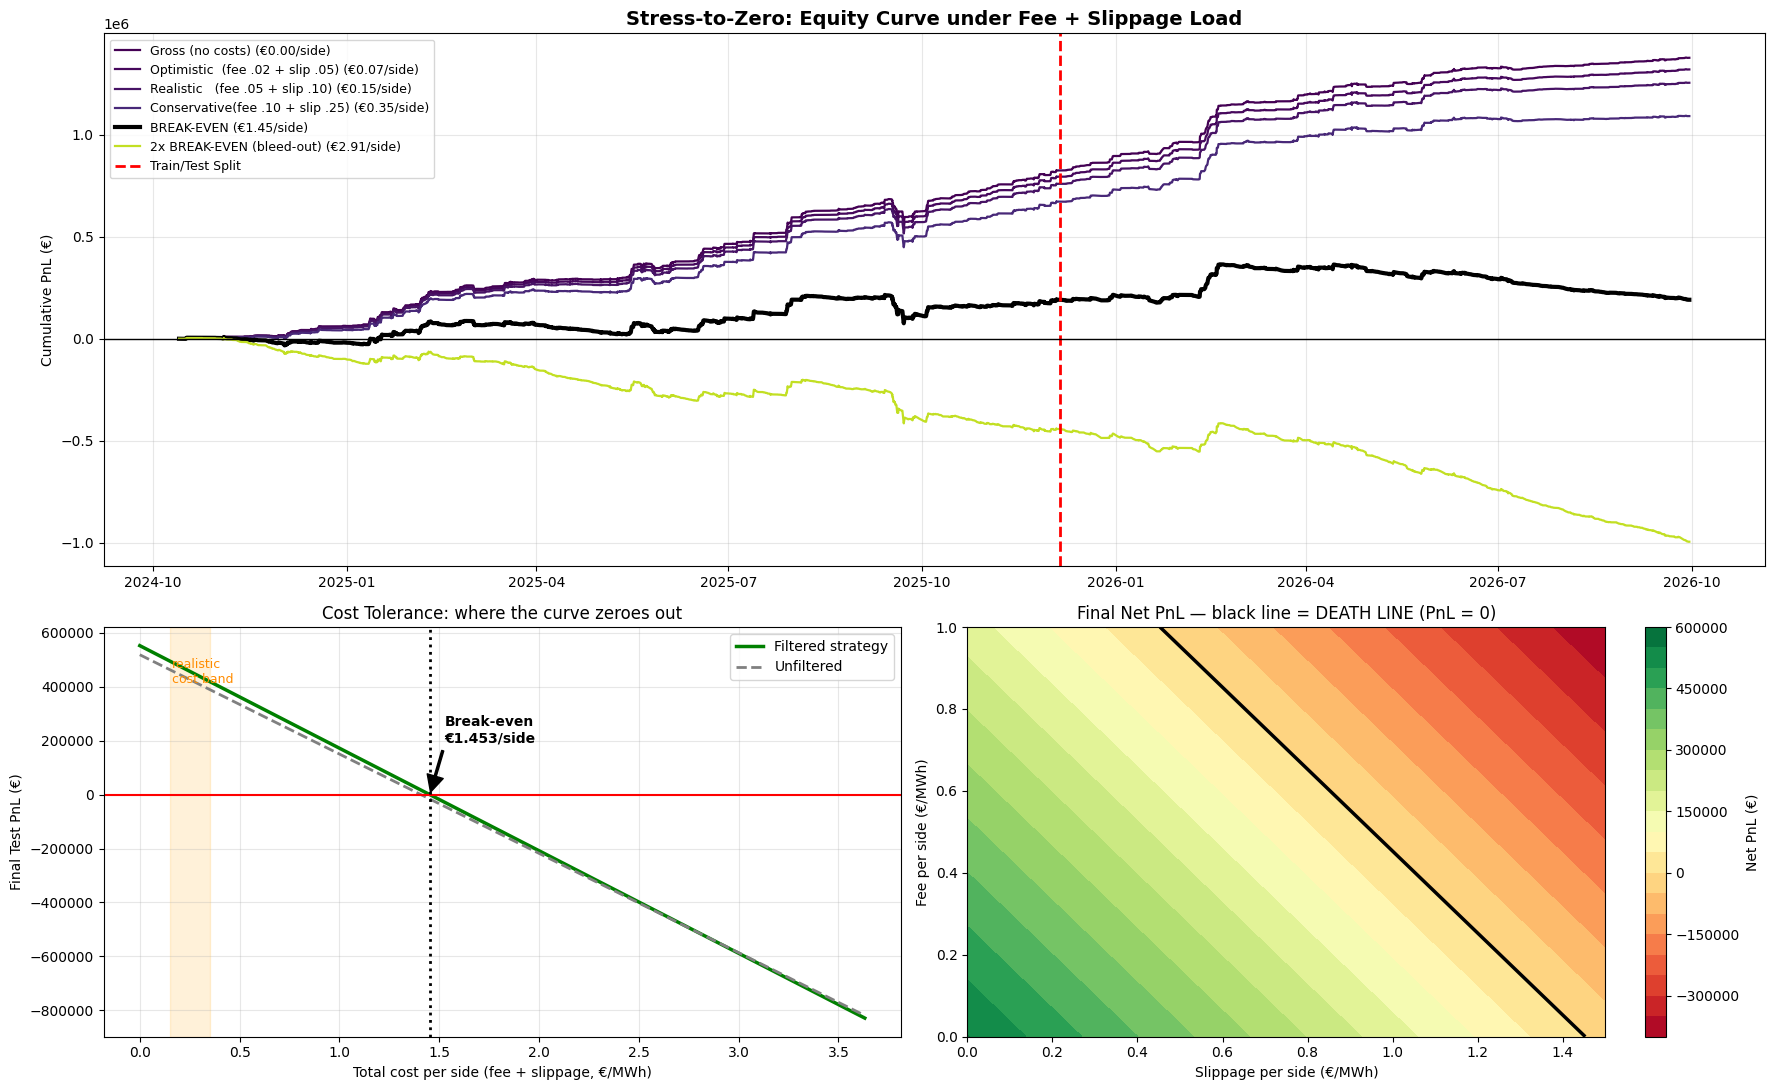


STRESS TEST VERDICT
At realistic costs (€0.05 fee + €0.10 slippage per side):
  Net PnL: €495,467  (89.7% of gross retained)
Cost headroom: 9.7x realistic costs before the equity curve zeroes out.
✅ ROBUST: gross edge comfortably absorbs realistic fees + slippage.
✅ Stress test plot saved to /kaggle/working/stress_test_fees_slippage.png


In [7]:
# =====================================
# 14. FINAL STRESS TEST: FEES & SLIPPAGE -> STRESS-TO-ZERO
# =====================================
print("\n[14/14] Stress-testing equity curve with fees & slippage...")

# --- Cost model ---
# A spread trade touches TWO legs (buy one zone, sell the other).
# fee  = exchange/broker fee per MWh per side
# slip = adverse price impact per MWh per side
# round-trip cost per MWh of spread = 2 * (fee + slip)
def net_pnl_series(cost_per_side, gross, executed_mask):
    cost_rt = 2.0 * cost_per_side
    return gross - executed_mask * TRADE_SIZE * cost_rt

def max_drawdown(cum):
    peak = np.maximum.accumulate(cum)
    return (cum - peak).min()

# Executed masks & gross PnL (filtered = our production strategy)
executed_f = (filtered_positions == 1) & (gate_test.values <= IMB_THRESHOLD)
gross_f    = filtered_test_pnl.copy()
executed_u = (test_pnl != 0)
gross_u    = test_pnl.copy()
executed_v = (val_pnl != 0)

n_trades   = int(executed_f.sum())
gross_total = gross_f.sum()

# --- 1) Analytic break-even: gross edge per traded MWh ---
breakeven_rt   = gross_total / (n_trades * TRADE_SIZE)   # €/MWh round-trip
breakeven_side = breakeven_rt / 2.0                      # €/MWh per side (fee+slip)

print(f"Executed test trades : {n_trades:,}")
print(f"Gross PnL (zero cost): €{gross_total:,.0f}")
print(f"Avg gross edge/trade : €{gross_total/n_trades:,.2f}  (= €{breakeven_rt:.3f}/MWh round-trip)")
print(f"⛔ BREAK-EVEN COST    : €{breakeven_side:.3f}/side  (€{breakeven_rt:.3f} round-trip) -> equity ends at ZERO")

# --- 2) Scenario table ---
scenarios = [
    ("Gross (no costs)",        0.00),
    ("Optimistic  (fee .02 + slip .05)", 0.07),
    ("Realistic   (fee .05 + slip .10)", 0.15),
    ("Conservative(fee .10 + slip .25)", 0.35),
    ("BREAK-EVEN",              breakeven_side),
    ("2x BREAK-EVEN (bleed-out)", 2.0 * breakeven_side),
]

print("\n" + "="*95)
print(f"{'Scenario':<32}{'€/side':>8}{'€/MWh RT':>10}{'Net PnL':>16}{'% of Gross':>12}{'Max DD':>14}")
print("="*95)
for label, c in scenarios:
    net = net_pnl_series(c, gross_f, executed_f)
    cum = np.cumsum(net)
    print(f"{label:<32}{c:>8.3f}{2*c:>10.3f}{net.sum():>16,.0f}{100*net.sum()/max(gross_total,1):>11.1f}%{max_drawdown(cum):>14,.0f}")
print("="*95)

# --- 3) Cost sweep: final equity vs cost level (filtered vs unfiltered) ---
cost_grid = np.linspace(0, 2.5 * breakeven_side, 300)
finals_f = [net_pnl_series(c, gross_f, executed_f).sum() for c in cost_grid]
finals_u = [net_pnl_series(c, gross_u, executed_u).sum() for c in cost_grid]

# --- 4) Fee x Slippage heatmap (final net PnL) ---
fee_grid  = np.array([0.0, 0.02, 0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.00])
slip_grid = np.array([0.0, 0.05, 0.10, 0.20, 0.35, 0.50, 0.75, 1.00, 1.50])
Z = np.zeros((len(fee_grid), len(slip_grid)))
for i, f in enumerate(fee_grid):
    for j, s in enumerate(slip_grid):
        Z[i, j] = net_pnl_series(f + s, gross_f, executed_f).sum()

# --- 5) Plots ---
fig = plt.figure(figsize=(18, 11))
gs = fig.add_gridspec(2, 2, height_ratios=[1.3, 1])

# (A) Equity curve family under increasing costs (validation + test, continuous)
axA = fig.add_subplot(gs[0, :])
for label, c in scenarios:
    net_v = net_pnl_series(c, val_pnl, executed_v)
    net_t = net_pnl_series(c, gross_f, executed_f)
    cum = np.concatenate([np.cumsum(net_v), np.cumsum(net_v)[-1] + np.cumsum(net_t)])
    idx = y_val_rolling.index.append(y_test_full.index)
    lw = 3.0 if label == "BREAK-EVEN" else 1.6
    col = 'black' if label == "BREAK-EVEN" else plt.cm.viridis(c / (2.2 * breakeven_side + 1e-9))
    axA.plot(idx, cum, label=f"{label} (€{c:.2f}/side)", linewidth=lw, color=col)
axA.axvline(y_test_full.index[0], color='red', ls='--', lw=2, label='Train/Test Split')
axA.axhline(0, color='black', lw=1)
axA.set_title('Stress-to-Zero: Equity Curve under Fee + Slippage Load', fontsize=14, fontweight='bold')
axA.set_ylabel('Cumulative PnL (€)')
axA.legend(loc='upper left', fontsize=9)
axA.grid(alpha=0.3)

# (B) Final equity vs cost per side
axB = fig.add_subplot(gs[1, 0])
axB.plot(cost_grid, finals_f, color='green', lw=2.5, label='Filtered strategy')
axB.plot(cost_grid, finals_u, color='gray', ls='--', lw=2, label='Unfiltered')
axB.axhline(0, color='red', lw=1.5)
axB.axvline(breakeven_side, color='black', lw=2, ls=':')
axB.annotate(f'Break-even\n€{breakeven_side:.3f}/side', xy=(breakeven_side, 0),
             xytext=(breakeven_side * 1.05, max(finals_f) * 0.35),
             arrowprops=dict(facecolor='black', shrink=0.05, width=1.5), fontweight='bold')
axB.axvspan(0.05 + 0.10, 0.10 + 0.25, color='orange', alpha=0.15)
axB.text(0.16, max(finals_f) * 0.75, 'realistic\ncost band', fontsize=9, color='darkorange')
axB.set_xlabel('Total cost per side (fee + slippage, €/MWh)')
axB.set_ylabel('Final Test PnL (€)')
axB.set_title('Cost Tolerance: where the curve zeroes out')
axB.legend(); axB.grid(alpha=0.3)

# (C) Fee x Slippage heatmap with zero contour
axC = fig.add_subplot(gs[1, 1])
X, Y = np.meshgrid(slip_grid, fee_grid)
cs = axC.contourf(X, Y, Z, levels=20, cmap='RdYlGn')
axC.contour(X, Y, Z, levels=[0], colors='black', linewidths=2.5)
axC.set_xlabel('Slippage per side (€/MWh)')
axC.set_ylabel('Fee per side (€/MWh)')
axC.set_title('Final Net PnL — black line = DEATH LINE (PnL = 0)')
plt.colorbar(cs, ax=axC, label='Net PnL (€)')

plt.tight_layout()
plt.savefig('/kaggle/working/stress_test_fees_slippage.png', dpi=150)
plt.show()

# --- 6) Verdict ---
realistic_side = 0.05 + 0.10
net_real = net_pnl_series(realistic_side, gross_f, executed_f).sum()
headroom = breakeven_side / realistic_side
print("\n" + "="*80)
print("STRESS TEST VERDICT")
print("="*80)
print(f"At realistic costs (€0.05 fee + €0.10 slippage per side):")
print(f"  Net PnL: €{net_real:,.0f}  ({100*net_real/gross_total:.1f}% of gross retained)")
print(f"Cost headroom: {headroom:.1f}x realistic costs before the equity curve zeroes out.")
if headroom < 1:
    print("❌ STRATEGY IS NOT TRADABLE: realistic costs exceed the gross edge.")
elif headroom < 3:
    print("⚠️  THIN MARGIN: strategy survives but cost estimation error can kill it.")
else:
    print("✅ ROBUST: gross edge comfortably absorbs realistic fees + slippage.")
print("="*80)
print("✅ Stress test plot saved to /kaggle/working/stress_test_fees_slippage.png")